# Faster R-CNN full-swath test-set inference

Runs the best Faster R-CNN checkpoint (`runs/frcnn_frgb/weights/best.pt`) on the
held-out **test split** (254 passes, from `split_assignments.csv`), on the
complete, unclipped SWOT L3 NetCDF files, and saves a NetCDF per pass with an
internal-wave detection mask and a confidence mask -- mirroring what
`infrence.ipynb` does for the YOLO model.

The model input is the `scientific_rgb_composite` image it was trained on
(R = SSHA, G = Gaussian high-pass, B = gradient magnitude), reproduced here
from the raw NetCDF fields rather than reusing the single-channel magma
pipeline the YOLO notebook uses -- the two models were trained on genuinely
different image types.

In [ ]:
import sys
from pathlib import Path

_MODEL_DIR = Path.cwd()
_SRC_DIR = _MODEL_DIR / "src"

for _p in (_SRC_DIR, _MODEL_DIR):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

from configs import config

REPO_ROOT = config.REPO_ROOT
print(REPO_ROOT)

## Build the test-split NetCDF subset

In [2]:
import csv
import shutil

SPLIT_ASSIGNMENTS_CSV = (
    REPO_ROOT
    / "data"
    / "Labeled_SWOT_L3_BOB_dataset"
    / "composite_grouped_yolo_splits"
    / "split_assignments.csv"
)

SOURCE_FOLDER = REPO_ROOT / "data" / "data_w_preprocessing"
OUTPUT_FOLDER = REPO_ROOT / "data" / "data_w_preprocessing_test_subset"

OVERWRITE = True

if not SPLIT_ASSIGNMENTS_CSV.exists():
    raise FileNotFoundError(f"Split assignments CSV not found: {SPLIT_ASSIGNMENTS_CSV}")

if not SOURCE_FOLDER.exists():
    raise FileNotFoundError(f"Source folder does not exist: {SOURCE_FOLDER}")

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

with open(SPLIT_ASSIGNMENTS_CSV, "r") as f:
    rows = list(csv.DictReader(f))

test_stems = sorted(
    {Path(row["image_name"]).stem for row in rows if row["split"] == "test"}
)

print(f"Test-split chips listed in split_assignments.csv: {len(test_stems)}")

copied_files = []
missing_files = []

for file_index, stem in enumerate(test_stems, start=1):
    source_file = SOURCE_FOLDER / f"{stem}.nc"
    output_file = OUTPUT_FOLDER / f"{stem}.nc"

    if not source_file.exists():
        missing_files.append(source_file)
        print(f"[{file_index}/{len(test_stems)}] Missing source NetCDF: {source_file.name}")
        continue

    if output_file.exists() and not OVERWRITE:
        continue

    shutil.copy2(source_file, output_file)
    copied_files.append(source_file)

    print(f"[{file_index}/{len(test_stems)}] Copied {source_file.name}")

print()
print("=" * 70)
print(f"Test-split NetCDF files copied: {len(copied_files)}")
print(f"Missing source files:           {len(missing_files)}")
print(f"Output folder:                  {OUTPUT_FOLDER}")

Test-split chips listed in split_assignments.csv: 254
[1/254] Copied SWOT_L3_LR_SSH_Expert_001_314_20230801T095643_20230801T104809_v3.0.nc
[2/254] Copied SWOT_L3_LR_SSH_Expert_001_329_20230801T224825_20230801T233952_v3.0.nc
[3/254] Copied SWOT_L3_LR_SSH_Expert_001_342_20230802T095714_20230802T104840_v3.0.nc
[4/254] Copied SWOT_L3_LR_SSH_Expert_001_370_20230803T095745_20230803T104912_v3.0.nc
[5/254] Copied SWOT_L3_LR_SSH_Expert_002_008_20230811T081900_20230811T091027_v3.0.nc
[6/254] Copied SWOT_L3_LR_SSH_Expert_002_301_20230821T193259_20230821T202425_v3.0.nc
[7/254] Copied SWOT_L3_LR_SSH_Expert_002_314_20230822T064148_20230822T073314_v3.0.nc
[8/254] Copied SWOT_L3_LR_SSH_Expert_002_329_20230822T193330_20230822T202456_v3.0.nc
[9/254] Copied SWOT_L3_LR_SSH_Expert_002_342_20230823T064219_20230823T073345_v3.0.nc
[10/254] Copied SWOT_L3_LR_SSH_Expert_002_370_20230824T064250_20230824T073416_v3.0.nc
[11/254] Copied SWOT_L3_LR_SSH_Expert_003_008_20230901T050405_20230901T055532_v3.0.nc
[12/254] 

[60/254] Copied SWOT_L3_LR_SSH_Expert_013_008_20240327T203452_20240327T212618_v3.0.nc
[61/254] Copied SWOT_L3_LR_SSH_Expert_013_301_20240407T074851_20240407T084017_v3.0.nc
[62/254] Copied SWOT_L3_LR_SSH_Expert_013_314_20240407T185740_20240407T194906_v3.0.nc
[63/254] Copied SWOT_L3_LR_SSH_Expert_013_329_20240408T074922_20240408T084048_v3.0.nc


[64/254] Copied SWOT_L3_LR_SSH_Expert_013_342_20240408T185811_20240408T194937_v3.0.nc
[65/254] Copied SWOT_L3_LR_SSH_Expert_013_370_20240409T185842_20240409T195008_v3.0.nc
[66/254] Copied SWOT_L3_LR_SSH_Expert_014_008_20240417T171958_20240417T181124_v3.0.nc
[67/254] Copied SWOT_L3_LR_SSH_Expert_014_301_20240428T043356_20240428T052523_v3.0.nc
[68/254] Copied SWOT_L3_LR_SSH_Expert_014_314_20240428T154245_20240428T163411_v3.0.nc
[69/254] Copied SWOT_L3_LR_SSH_Expert_014_329_20240429T043427_20240429T052553_v3.0.nc
[70/254] Copied SWOT_L3_LR_SSH_Expert_014_342_20240429T154316_20240429T163442_v3.0.nc
[71/254] Copied SWOT_L3_LR_SSH_Expert_014_370_20240430T154347_20240430T163513_v3.0.nc
[72/254] Copied SWOT_L3_LR_SSH_Expert_015_008_20240508T140501_20240508T145628_v3.0.nc
[73/254] Copied SWOT_L3_LR_SSH_Expert_015_301_20240519T011901_20240519T021026_v3.0.nc
[74/254] Copied SWOT_L3_LR_SSH_Expert_015_314_20240519T122749_20240519T131914_v3.0.nc
[75/254] Copied SWOT_L3_LR_SSH_Expert_015_329_20240520

[125/254] Copied SWOT_L3_LR_SSH_Expert_024_370_20241125T071436_20241125T080603_v3.0.nc
[126/254] Copied SWOT_L3_LR_SSH_Expert_025_008_20241203T053550_20241203T062717_v3.0.nc
[127/254] Copied SWOT_L3_LR_SSH_Expert_025_301_20241213T164949_20241213T174116_v3.0.nc
[128/254] Copied SWOT_L3_LR_SSH_Expert_025_314_20241214T035838_20241214T045004_v3.0.nc


[129/254] Copied SWOT_L3_LR_SSH_Expert_025_329_20241214T165020_20241214T174147_v3.0.nc
[130/254] Copied SWOT_L3_LR_SSH_Expert_026_008_20241224T022055_20241224T031221_v3.0.nc
[131/254] Copied SWOT_L3_LR_SSH_Expert_026_314_20250104T004343_20250104T013509_v3.0.nc
[132/254] Copied SWOT_L3_LR_SSH_Expert_026_329_20250104T133525_20250104T142651_v3.0.nc
[133/254] Copied SWOT_L3_LR_SSH_Expert_026_342_20250105T004414_20250105T013540_v3.0.nc
[134/254] Copied SWOT_L3_LR_SSH_Expert_026_355_20250105T115302_20250105T124429_v3.0.nc
[135/254] Copied SWOT_L3_LR_SSH_Expert_026_370_20250106T004445_20250106T013611_v3.0.nc
[136/254] Copied SWOT_L3_LR_SSH_Expert_027_329_20250125T102030_20250125T111156_v3.0.nc
[137/254] Copied SWOT_L3_LR_SSH_Expert_028_008_20250203T195103_20250203T204229_v3.0.nc
[138/254] Copied SWOT_L3_LR_SSH_Expert_028_301_20250214T070502_20250214T075629_v3.0.nc
[139/254] Copied SWOT_L3_LR_SSH_Expert_028_314_20250214T181351_20250214T190518_v3.0.nc
[140/254] Copied SWOT_L3_LR_SSH_Expert_028_

[197/254] Copied SWOT_L3_LR_SSH_Expert_039_342_20251003T063014_20251003T072140_v3.0.nc
[198/254] Copied SWOT_L3_LR_SSH_Expert_039_355_20251003T173903_20251003T183029_v3.0.nc
[199/254] Copied SWOT_L3_LR_SSH_Expert_039_370_20251004T063045_20251004T072212_v3.0.nc
[200/254] Copied SWOT_L3_LR_SSH_Expert_040_008_20251012T045200_20251012T054326_v3.0.nc
[201/254] Copied SWOT_L3_LR_SSH_Expert_040_301_20251022T160600_20251022T165726_v3.0.nc
[202/254] Copied SWOT_L3_LR_SSH_Expert_040_314_20251023T031449_20251023T040615_v3.0.nc
[203/254] Copied SWOT_L3_LR_SSH_Expert_040_329_20251023T160631_20251023T165758_v3.0.nc
[204/254] Copied SWOT_L3_LR_SSH_Expert_040_342_20251024T031520_20251024T040646_v3.0.nc
[205/254] Copied SWOT_L3_LR_SSH_Expert_040_355_20251024T142409_20251024T151535_v3.0.nc
[206/254] Copied SWOT_L3_LR_SSH_Expert_041_008_20251102T013706_20251102T022832_v3.0.nc
[207/254] Copied SWOT_L3_LR_SSH_Expert_041_301_20251112T125103_20251112T134230_v3.0.nc
[208/254] Copied SWOT_L3_LR_SSH_Expert_041_

## Load the best Faster R-CNN checkpoint

In [ ]:
import json

from inference.rgb_composite_frcnn_detector import RGBCompositeFasterRCNNDetector

INPUT_DIR = OUTPUT_FOLDER
FILE_PATTERN = "*.nc"

MODEL_PATH = config.DEFAULT_RUNS_DIR / "frcnn_frgb" / "weights" / "best.pt"
EVAL_SUMMARY_PATH = (
    config.DEFAULT_RUNS_DIR
    / "frcnn_frgb"
    / "eval"
    / "faster_rcnn_best_conf_fixed_f1_summary.json"
)

# Use the confidence threshold that maximizes F1 on the validation split
# (selected by faster-rcnn/src/evaluation/evaluate.py), falling back to 0.65 if
# the eval summary is unavailable.
if EVAL_SUMMARY_PATH.exists():
    with open(EVAL_SUMMARY_PATH) as f:
        CONFIDENCE_THRESHOLD = json.load(f)["selected_confidence"]
else:
    CONFIDENCE_THRESHOLD = 0.65

OUTPUT_DIR = (
    REPO_ROOT
    / "data"
    / f"frcnn_conf_{int(round(CONFIDENCE_THRESHOLD * 100)):02d}_detection_results"
)

MASK_VARIABLE = "isw_detection_mask"
CONFIDENCE_MASK_VARIABLE = "isw_detection_confidence"

OVERWRITE = False

if not INPUT_DIR.exists():
    raise FileNotFoundError(f"Input folder does not exist: {INPUT_DIR}")

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Faster R-CNN checkpoint does not exist: {MODEL_PATH}")

NETCDF_OUTPUT_DIR = OUTPUT_DIR / "netcdf"
IMAGE_OUTPUT_DIR = OUTPUT_DIR / "images"
TEXT_OUTPUT_DIR = OUTPUT_DIR / "text"

for out_dir in (NETCDF_OUTPUT_DIR, IMAGE_OUTPUT_DIR, TEXT_OUTPUT_DIR):
    out_dir.mkdir(parents=True, exist_ok=True)

netcdf_files = sorted(INPUT_DIR.glob(FILE_PATTERN))

if not netcdf_files:
    raise FileNotFoundError(
        f"No NetCDF files matching {FILE_PATTERN!r} were found in {INPUT_DIR}"
    )

print(f"Confidence threshold (val-selected F1 operating point): {CONFIDENCE_THRESHOLD}")
print(f"Model checkpoint: {MODEL_PATH}")
print(f"Test files to process: {len(netcdf_files)}")

detector = RGBCompositeFasterRCNNDetector(model_path=MODEL_PATH)
print(f"Device: {detector.device}")
print(f"Class names: {detector.class_names}")

## Run detection on every test-split NetCDF file

In [4]:
successful_files = []
failed_files = []
skipped_files = []

for file_index, input_file in enumerate(netcdf_files, start=1):
    output_netcdf = NETCDF_OUTPUT_DIR / input_file.name
    output_image = IMAGE_OUTPUT_DIR / f"{input_file.stem}_detections.png"
    output_text = TEXT_OUTPUT_DIR / f"{input_file.stem}_detections.txt"

    if output_netcdf.exists() and not OVERWRITE:
        print(f"[{file_index}/{len(netcdf_files)}] Skipping existing file: {output_netcdf.name}")
        skipped_files.append(input_file)
        continue

    processed_ds = None

    try:
        processed_ds, detection_text, boxed_image, detections = detector.detect_on_l3_file(
            l3_file=input_file,
            conf=CONFIDENCE_THRESHOLD,
            mask_var_name=MASK_VARIABLE,
            conf_mask_var_name=CONFIDENCE_MASK_VARIABLE,
        )

        # Saved NetCDF containing:
        #   - isw_detection_mask
        #   - isw_detection_confidence
        #   - rgb_composite_ssha / rgb_composite_gaussian_highpass / rgb_composite_gradient_magnitude
        processed_ds.to_netcdf(output_netcdf)

        boxed_image.save(output_image)
        output_text.write_text(detection_text, encoding="utf-8")

        successful_files.append(input_file)

        print(
            f"[{file_index}/{len(netcdf_files)}] Processed {input_file.name} | "
            f"detections={len(detections)} | netcdf={output_netcdf.name}"
        )

    except Exception as error:
        failed_files.append({"file": input_file, "error": str(error)})
        print(f"[{file_index}/{len(netcdf_files)}] FAILED {input_file.name}: {error}")

    finally:
        if processed_ds is not None:
            processed_ds.close()

print()
print("=" * 70)
print("Processing complete")
print("=" * 70)
print(f"Input files:       {len(netcdf_files)}")
print(f"Successful files:  {len(successful_files)}")
print(f"Skipped files:     {len(skipped_files)}")
print(f"Failed files:      {len(failed_files)}")
print(f"Output directory:  {OUTPUT_DIR}")

if failed_files:
    print()
    print("Failed files:")
    for failure in failed_files:
        print(f"  {failure['file'].name}: {failure['error']}")

[1/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_001_314_20230801T095643_20230801T104809_v3.0.nc
[2/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_001_329_20230801T224825_20230801T233952_v3.0.nc
[3/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_001_342_20230802T095714_20230802T104840_v3.0.nc
[4/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_001_370_20230803T095745_20230803T104912_v3.0.nc
[5/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_002_008_20230811T081900_20230811T091027_v3.0.nc
[6/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_002_301_20230821T193259_20230821T202425_v3.0.nc
[7/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_002_314_20230822T064148_20230822T073314_v3.0.nc
[8/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_002_329_20230822T193330_20230822T202456_v3.0.nc
[9/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_002_342_20230823T064219_20230823T073345_v3.0.nc
[10/254] Skipping existing file: SWOT_L3_LR_SSH_Expert_002_370_20230824T064250_202

## Evaluation against ground truth

Mirrors the block-level evaluation in `gaussian_test_data.ipynb` (20x20
majority-vote blocks, precision/recall/F1/F0.5/IoU, PR AUC, ROC AUC), but does
**not** repeat the inference above.

One difference from `gaussian_test_data.ipynb`: that notebook reads a
`block_mask` variable that was baked into `data/test/*_labeled.nc` ahead of
time. The NetCDF files produced above come from `data_w_preprocessing`
instead, which has no such baked-in ground truth. Ground truth is rasterized
here straight from the normalized YOLO-format test-split label files used to
train and evaluate this same Faster R-CNN checkpoint
(`composite_grouped_yolo_splits/scientific_rgb_composite/labels/test/`), using
the exact inverse of the orientation transform the detector applies -- checked
to line up pixel-for-pixel with `isw_detection_mask` (>98% IoU on a sample
detection).

In [ ]:
import sys
from pathlib import Path

_MODEL_DIR = Path.cwd()
_SRC_DIR = _MODEL_DIR / "src"

for _p in (_SRC_DIR, _MODEL_DIR):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import json

import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

from configs import config
from inference.rgb_composite_frcnn_detector import RGBCompositeFasterRCNNDetector

REPO_ROOT = config.REPO_ROOT

# Re-derive the paths the inference cells above used, without re-running detection.
EVAL_SUMMARY_PATH = (
    config.DEFAULT_RUNS_DIR
    / "frcnn_frgb"
    / "eval"
    / "faster_rcnn_best_conf_fixed_f1_summary.json"
)

if EVAL_SUMMARY_PATH.exists():
    with open(EVAL_SUMMARY_PATH) as f:
        CONFIDENCE_THRESHOLD = json.load(f)["selected_confidence"]
else:
    CONFIDENCE_THRESHOLD = 0.65

DETECTION_RESULTS_DIR = (
    REPO_ROOT
    / "data"
    / f"frcnn_conf_{int(round(CONFIDENCE_THRESHOLD * 100)):02d}_detection_results"
)
NETCDF_RESULTS_DIR = DETECTION_RESULTS_DIR / "netcdf"

LABELS_TEST_DIR = (
    REPO_ROOT
    / "data"
    / "Labeled_SWOT_L3_BOB_dataset"
    / "composite_grouped_yolo_splits"
    / "scientific_rgb_composite"
    / "labels"
    / "test"
)

if not NETCDF_RESULTS_DIR.exists():
    raise FileNotFoundError(
        f"No detection results found at {NETCDF_RESULTS_DIR}. "
        "Run the inference cells above first."
    )

PREDICTED_MASK_VAR = "isw_detection_mask"
BACKGROUND_VAR = "gaussian_filter_highpass"

BLOCK_HEIGHT = 20
BLOCK_WIDTH = 20

# Pixel values >= 0.5 are positive.
PIXEL_POSITIVE_THRESHOLD = 0.5

# Strict majority: more than 50% of a block's finite pixels must be positive.
BLOCK_MAJORITY_THRESHOLD = 0.5

# The resulting block predictions are binary, so evaluate at 0.5.
BLOCK_PREDICTION_THRESHOLD = 0.5

# Ignore blocks with no finite background pixels (empty swath regions).
IGNORE_BLOCKS_WITH_NO_BACKGROUND_DATA = True

PER_FILE_CSV = DETECTION_RESULTS_DIR / "block_metrics_per_file.csv"
OVERALL_CSV = DETECTION_RESULTS_DIR / "block_metrics_overall.csv"

print(f"Detection results: {NETCDF_RESULTS_DIR}")
print(f"Ground-truth labels: {LABELS_TEST_DIR}")


def ground_truth_mask_for(stem, original_shape):
    label_path = LABELS_TEST_DIR / f"{stem}.txt"
    return RGBCompositeFasterRCNNDetector.yolo_label_to_original_mask(
        label_path, original_shape
    )


# ============================================================
# Array / block helpers
# ============================================================

def get_2d_array(data_array):
    array = np.asarray(data_array.values)
    array = np.squeeze(array)

    if array.ndim != 2:
        raise ValueError(
            f"Expected {data_array.name!r} to be 2D after squeezing, got shape {array.shape}."
        )

    return array


def crop_to_complete_blocks(array, block_height, block_width):
    array = np.asarray(array)
    height, width = array.shape

    cropped_height = (height // block_height) * block_height
    cropped_width = (width // block_width) * block_width

    if cropped_height == 0 or cropped_width == 0:
        raise ValueError(
            f"Array shape {array.shape} is too small for {block_height}x{block_width} blocks."
        )

    return array[:cropped_height, :cropped_width]


def binary_mask_to_majority_blocks(
    mask,
    block_height=BLOCK_HEIGHT,
    block_width=BLOCK_WIDTH,
    pixel_positive_threshold=PIXEL_POSITIVE_THRESHOLD,
    majority_threshold=BLOCK_MAJORITY_THRESHOLD,
):
    """Convert a pixel-level mask into a block-level binary mask.

    A block is positive when more than majority_threshold of its finite
    pixels are positive. Also returns the per-block positive fraction, used
    as a continuous score for PR AUC / ROC AUC.
    """
    mask = np.asarray(mask, dtype=np.float32)
    mask = crop_to_complete_blocks(mask, block_height, block_width)

    height, width = mask.shape
    block_rows = height // block_height
    block_columns = width // block_width

    finite_pixels = np.isfinite(mask)
    positive_pixels = finite_pixels & (mask >= pixel_positive_threshold)

    finite_blocks = finite_pixels.reshape(block_rows, block_height, block_columns, block_width)
    positive_blocks = positive_pixels.reshape(block_rows, block_height, block_columns, block_width)

    finite_count = finite_blocks.sum(axis=(1, 3))
    positive_count = positive_blocks.sum(axis=(1, 3))

    valid_blocks = finite_count > 0

    positive_fraction = np.zeros((block_rows, block_columns), dtype=np.float32)
    positive_fraction[valid_blocks] = positive_count[valid_blocks] / finite_count[valid_blocks]

    block_mask = (positive_fraction > majority_threshold).astype(np.uint8)
    block_mask[~valid_blocks] = 0

    return block_mask, valid_blocks, positive_fraction


def background_to_valid_blocks(background, block_height=BLOCK_HEIGHT, block_width=BLOCK_WIDTH):
    background = crop_to_complete_blocks(
        np.asarray(background, dtype=np.float32), block_height, block_width
    )

    height, width = background.shape
    block_rows = height // block_height
    block_columns = width // block_width

    finite_pixels = np.isfinite(background)
    finite_blocks = finite_pixels.reshape(block_rows, block_height, block_columns, block_width)

    return finite_blocks.sum(axis=(1, 3)) > 0


def calculate_binary_metrics(y_true, y_prob, threshold):
    y_true = np.asarray(y_true, dtype=bool).reshape(-1)
    y_prob = np.asarray(y_prob, dtype=np.float32).reshape(-1)

    y_pred = y_prob >= threshold

    tp = int(np.logical_and(y_true, y_pred).sum())
    fp = int(np.logical_and(~y_true, y_pred).sum())
    tn = int(np.logical_and(~y_true, ~y_pred).sum())
    fn = int(np.logical_and(y_true, ~y_pred).sum())

    total = tp + fp + tn + fn

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    accuracy = (tp + tn) / total if total > 0 else 0.0
    f1 = 2.0 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    beta_squared = 0.5**2
    f0_5 = (
        (1.0 + beta_squared) * precision * recall / (beta_squared * precision + recall)
        if (beta_squared * precision + recall) > 0
        else 0.0
    )

    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0
    balanced_accuracy = 0.5 * (recall + specificity)
    label_positive_rate = float(y_true.mean()) if total > 0 else 0.0
    pred_positive_rate = float(y_pred.mean()) if total > 0 else 0.0
    false_positive_rate = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    false_discovery_rate = fp / (tp + fp) if (tp + fp) > 0 else 0.0

    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "f1": float(f1),
        "f0_5": float(f0_5),
        "iou": float(iou),
        "balanced_accuracy": float(balanced_accuracy),
        "label_positive_rate": float(label_positive_rate),
        "pred_positive_rate": float(pred_positive_rate),
        "false_positive_rate": float(false_positive_rate),
        "false_discovery_rate": float(false_discovery_rate),
        "tp": tp,
        "fp": fp,
        "tn": tn,
        "fn": fn,
        "total_blocks": total,
    }


def calculate_auc_metrics(y_true, y_score):
    y_true = np.asarray(y_true, dtype=np.uint8).reshape(-1)
    y_score = np.asarray(y_score, dtype=np.float32).reshape(-1)

    finite_mask = np.isfinite(y_score)
    y_true = y_true[finite_mask]
    y_score = y_score[finite_mask]

    if y_true.size == 0:
        return {"pr_auc": np.nan, "roc_auc": np.nan}

    unique_labels = np.unique(y_true)

    if np.any(y_true == 1):
        precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_score)
        pr_auc = auc(recall_curve[::-1], precision_curve[::-1])
    else:
        pr_auc = np.nan

    roc_auc = roc_auc_score(y_true, y_score) if unique_labels.size == 2 else np.nan

    return {"pr_auc": float(pr_auc), "roc_auc": float(roc_auc)}

## Qualitative check: one sample file

Sample file: SWOT_L3_LR_SSH_Expert_002_008_20230811T081900_20230811T091027_v3.0.nc


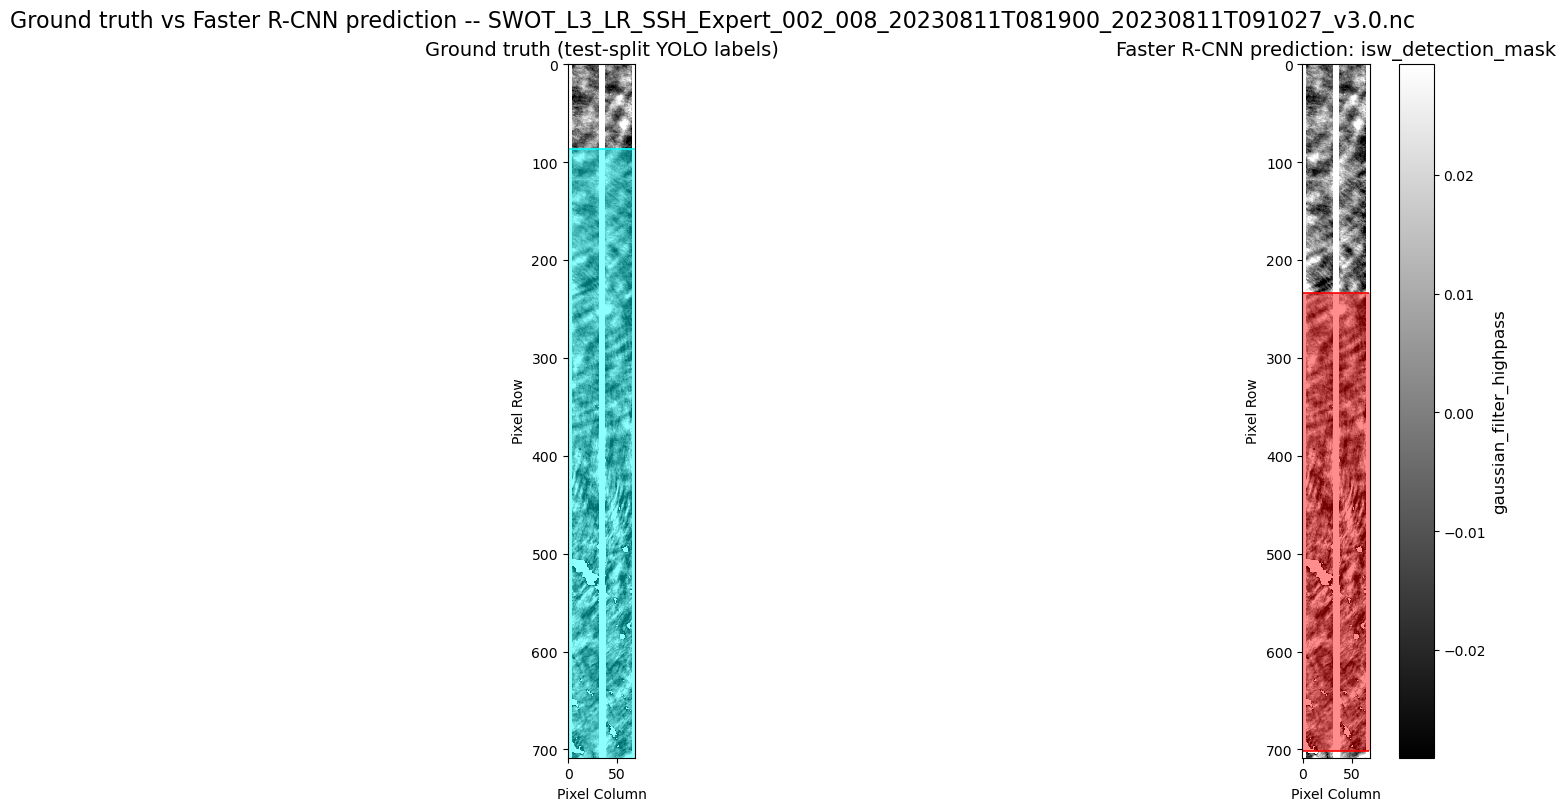

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

LOW_PERCENTILE = 2.0
HIGH_PERCENTILE = 98.0
MASK_ALPHA = 0.45
FIGURE_SIZE = (16, 8)

netcdf_result_files = sorted(NETCDF_RESULTS_DIR.glob("*.nc"))

if not netcdf_result_files:
    raise FileNotFoundError(f"No NetCDF results found in {NETCDF_RESULTS_DIR}")

# Prefer a file with both a predicted and a ground-truth detection.
sample_path = None
for candidate in netcdf_result_files:
    label_path = LABELS_TEST_DIR / f"{candidate.stem}.txt"
    if label_path.exists() and label_path.stat().st_size > 0:
        with xr.open_dataset(candidate) as ds:
            if int(ds[PREDICTED_MASK_VAR].values.sum()) > 0:
                sample_path = candidate
                break

if sample_path is None:
    sample_path = netcdf_result_files[0]

print(f"Sample file: {sample_path.name}")

ds = xr.open_dataset(sample_path)
try:
    background = get_2d_array(ds[BACKGROUND_VAR]).astype(np.float32)
    predicted_mask = get_2d_array(ds[PREDICTED_MASK_VAR])
    predicted_mask = (predicted_mask > 0).astype(np.uint8)

    ground_truth_mask = ground_truth_mask_for(sample_path.stem, predicted_mask.shape)

    finite_background = background[np.isfinite(background)]
    vmin, vmax = np.percentile(finite_background, [LOW_PERCENTILE, HIGH_PERCENTILE])
    if vmax <= vmin:
        vmin, vmax = float(np.nanmin(background)), float(np.nanmax(background))

    predicted_overlay = np.ma.masked_where(predicted_mask == 0, predicted_mask)
    ground_truth_overlay = np.ma.masked_where(ground_truth_mask == 0, ground_truth_mask)

    fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE, constrained_layout=True)

    axes[0].imshow(background, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest", origin="upper")
    axes[0].imshow(
        ground_truth_overlay, cmap=ListedColormap(["cyan"]), alpha=MASK_ALPHA,
        interpolation="nearest", origin="upper", vmin=0, vmax=1,
    )
    axes[0].contour(ground_truth_mask, levels=[0.5], colors=["cyan"], linewidths=1.2)
    axes[0].set_title("Ground truth (test-split YOLO labels)", fontsize=14)
    axes[0].set_xlabel("Pixel Column")
    axes[0].set_ylabel("Pixel Row")

    background_image_right = axes[1].imshow(
        background, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest", origin="upper"
    )
    axes[1].imshow(
        predicted_overlay, cmap=ListedColormap(["red"]), alpha=MASK_ALPHA,
        interpolation="nearest", origin="upper", vmin=0, vmax=1,
    )
    axes[1].contour(predicted_mask, levels=[0.5], colors=["red"], linewidths=1.2)
    axes[1].set_title(f"Faster R-CNN prediction: {PREDICTED_MASK_VAR}", fontsize=14)
    axes[1].set_xlabel("Pixel Column")
    axes[1].set_ylabel("Pixel Row")

    colorbar = fig.colorbar(background_image_right, ax=axes, orientation="vertical", fraction=0.025, pad=0.02)
    colorbar.set_label(BACKGROUND_VAR, fontsize=12)

    fig.suptitle(f"Ground truth vs Faster R-CNN prediction -- {sample_path.name}", fontsize=16)
    plt.show()
finally:
    ds.close()

## Single-file 20x20 block-mask evaluation

In [7]:
with xr.open_dataset(sample_path) as ds:
    background = get_2d_array(ds[BACKGROUND_VAR]).astype(np.float32)
    prediction_pixels = get_2d_array(ds[PREDICTED_MASK_VAR]).astype(np.float32)

ground_truth_pixels = ground_truth_mask_for(sample_path.stem, prediction_pixels.shape).astype(np.float32)

ground_truth_blocks, ground_truth_valid_blocks, ground_truth_positive_fraction = (
    binary_mask_to_majority_blocks(ground_truth_pixels)
)
prediction_blocks, prediction_valid_blocks, prediction_positive_fraction = (
    binary_mask_to_majority_blocks(prediction_pixels)
)
background_valid_blocks = background_to_valid_blocks(background)

valid_blocks = ground_truth_valid_blocks & prediction_valid_blocks
if IGNORE_BLOCKS_WITH_NO_BACKGROUND_DATA:
    valid_blocks &= background_valid_blocks

y_true = ground_truth_blocks[valid_blocks].astype(np.uint8)
y_pred = prediction_blocks[valid_blocks].astype(np.uint8)

metrics = calculate_binary_metrics(
    y_true=y_true, y_prob=y_pred.astype(np.float32), threshold=BLOCK_PREDICTION_THRESHOLD
)

print("=" * 70)
print("20x20 BLOCK-MASK ALIGNMENT EVALUATION -- single file")
print("=" * 70)
print(f"File: {sample_path.name}")
print(f"Block-grid shape: {ground_truth_blocks.shape}")
print(f"Valid evaluated blocks: {int(valid_blocks.sum())}")
print(f"Ground-truth positive blocks: {int(y_true.sum())}")
print(f"Predicted positive blocks:    {int(y_pred.sum())}")
print()

for key in [
    "accuracy", "precision", "recall", "specificity", "f1", "f0_5",
    "iou", "balanced_accuracy", "false_positive_rate", "false_discovery_rate",
]:
    print(f"{key:22s}{metrics[key]:.6f}")

print()
print(f"TP: {metrics['tp']}  FP: {metrics['fp']}  TN: {metrics['tn']}  FN: {metrics['fn']}")

metrics_table = pd.DataFrame({"metric": list(metrics.keys()), "value": list(metrics.values())})
display(metrics_table)

20x20 BLOCK-MASK ALIGNMENT EVALUATION -- single file
File: SWOT_L3_LR_SSH_Expert_002_008_20230811T081900_20230811T091027_v3.0.nc
Block-grid shape: (35, 3)
Valid evaluated blocks: 105
Ground-truth positive blocks: 93
Predicted positive blocks:    69

accuracy              0.771429
precision             1.000000
recall                0.741935
specificity           1.000000
f1                    0.851852
f0_5                  0.934959
iou                   0.741935
balanced_accuracy     0.870968
false_positive_rate   0.000000
false_discovery_rate  0.000000

TP: 69  FP: 0  TN: 12  FN: 24


,metric,value
0,threshold,0.500000
1,accuracy,0.771429
2,precision,1.000000
3,recall,0.741935
4,specificity,1.000000
5,f1,0.851852
6,f0_5,0.934959
7,iou,0.741935
8,balanced_accuracy,0.870968
9,label_positive_rate,0.885714


## Test-set 20x20 block-mask evaluation (all 254 files)

In [8]:
import traceback

per_file_rows = []
all_test_labels = []
all_test_predictions = []
all_test_scores = []

successful_files = 0
failed_files = 0

for file_index, nc_path in enumerate(netcdf_result_files, start=1):
    try:
        with xr.open_dataset(nc_path) as ds:
            background = get_2d_array(ds[BACKGROUND_VAR]).astype(np.float32)
            prediction_pixels = get_2d_array(ds[PREDICTED_MASK_VAR]).astype(np.float32)

        ground_truth_pixels = ground_truth_mask_for(
            nc_path.stem, prediction_pixels.shape
        ).astype(np.float32)

        if background.shape != prediction_pixels.shape:
            raise ValueError(
                f"Background shape {background.shape} != prediction shape {prediction_pixels.shape}"
            )

        ground_truth_blocks, ground_truth_valid_blocks, ground_truth_positive_fraction = (
            binary_mask_to_majority_blocks(ground_truth_pixels)
        )
        prediction_blocks, prediction_valid_blocks, prediction_positive_fraction = (
            binary_mask_to_majority_blocks(prediction_pixels)
        )
        background_valid_blocks = background_to_valid_blocks(background)

        valid_blocks = ground_truth_valid_blocks & prediction_valid_blocks
        if IGNORE_BLOCKS_WITH_NO_BACKGROUND_DATA:
            valid_blocks &= background_valid_blocks

        if not valid_blocks.any():
            raise ValueError("No valid 20x20 blocks were available.")

        y_true = ground_truth_blocks[valid_blocks].astype(np.uint8)
        y_pred = prediction_blocks[valid_blocks].astype(np.uint8)
        y_score = prediction_positive_fraction[valid_blocks].astype(np.float32)

        metrics = calculate_binary_metrics(
            y_true=y_true, y_prob=y_pred.astype(np.float32), threshold=BLOCK_PREDICTION_THRESHOLD
        )
        auc_metrics = calculate_auc_metrics(y_true=y_true, y_score=y_score)

        row = {
            "file": nc_path.name,
            "status": "success",
            "block_rows": ground_truth_blocks.shape[0],
            "block_columns": ground_truth_blocks.shape[1],
            "valid_blocks": int(valid_blocks.sum()),
            "ground_truth_positive_blocks": int(y_true.sum()),
            "predicted_positive_blocks": int(y_pred.sum()),
            **metrics,
            **auc_metrics,
            "error": "",
        }
        per_file_rows.append(row)

        all_test_labels.append(y_true)
        all_test_predictions.append(y_pred)
        all_test_scores.append(y_score)

        successful_files += 1

    except Exception as error:
        failed_files += 1
        print(f"[{file_index}/{len(netcdf_result_files)}] FAILED {nc_path.name}: {error}")
        traceback.print_exc()

        per_file_rows.append({
            "file": nc_path.name, "status": "failed",
            "block_rows": np.nan, "block_columns": np.nan,
            "valid_blocks": 0, "ground_truth_positive_blocks": 0, "predicted_positive_blocks": 0,
            "threshold": BLOCK_PREDICTION_THRESHOLD, "accuracy": np.nan, "precision": np.nan,
            "recall": np.nan, "specificity": np.nan, "f1": np.nan, "f0_5": np.nan, "iou": np.nan,
            "balanced_accuracy": np.nan, "label_positive_rate": np.nan, "pred_positive_rate": np.nan,
            "false_positive_rate": np.nan, "false_discovery_rate": np.nan,
            "pr_auc": np.nan, "roc_auc": np.nan,
            "tp": 0, "fp": 0, "tn": 0, "fn": 0, "total_blocks": 0, "error": str(error),
        })

per_file_results = pd.DataFrame(per_file_rows)
per_file_results.to_csv(PER_FILE_CSV, index=False)

if not all_test_labels:
    raise ValueError("No files were successfully evaluated.")

test_labels = np.concatenate(all_test_labels)
test_predictions = np.concatenate(all_test_predictions)
test_scores = np.concatenate(all_test_scores)

overall_metrics = calculate_binary_metrics(
    y_true=test_labels, y_prob=test_predictions.astype(np.float32), threshold=BLOCK_PREDICTION_THRESHOLD
)
overall_auc_metrics = calculate_auc_metrics(y_true=test_labels, y_score=test_scores)

overall_results = pd.DataFrame([{
    "test_set_directory": str(NETCDF_RESULTS_DIR),
    "files_found": len(netcdf_result_files),
    "successful_files": successful_files,
    "failed_files": failed_files,
    "block_height": BLOCK_HEIGHT,
    "block_width": BLOCK_WIDTH,
    "majority_threshold": BLOCK_MAJORITY_THRESHOLD,
    "valid_blocks": int(test_labels.size),
    "ground_truth_positive_blocks": int(test_labels.sum()),
    "predicted_positive_blocks": int(test_predictions.sum()),
    **overall_metrics,
    **overall_auc_metrics,
}])
overall_results.to_csv(OVERALL_CSV, index=False)

display_columns = [
    "file", "status", "valid_blocks", "ground_truth_positive_blocks", "predicted_positive_blocks",
    "accuracy", "precision", "recall", "specificity", "f1", "f0_5", "iou", "pr_auc", "roc_auc",
    "balanced_accuracy", "tp", "fp", "tn", "fn",
]

print("\n" + "=" * 80)
print("PER-FILE RESULTS")
print("=" * 80)
display(per_file_results[display_columns])

print("\n" + "=" * 80)
print("OVERALL TEST-SET RESULTS")
print("=" * 80)
print(f"Files found:           {len(netcdf_result_files)}")
print(f"Successful files:      {successful_files}")
print(f"Failed files:          {failed_files}")
print(f"Valid 20x20 blocks:    {test_labels.size}")
print(f"Ground-truth positive: {int(test_labels.sum())}")
print(f"Predicted positive:    {int(test_predictions.sum())}")
print()
print(f"Accuracy:              {overall_metrics['accuracy']:.6f}")
print(f"Precision:             {overall_metrics['precision']:.6f}")
print(f"Recall:                {overall_metrics['recall']:.6f}")
print(f"Specificity:           {overall_metrics['specificity']:.6f}")
print(f"F1:                    {overall_metrics['f1']:.6f}")
print(f"F0.5:                  {overall_metrics['f0_5']:.6f}")
print(f"IoU:                   {overall_metrics['iou']:.6f}")
print(f"PR AUC:                {overall_auc_metrics['pr_auc']:.6f}")
print(f"ROC AUC:               {overall_auc_metrics['roc_auc']:.6f}")
print(f"Balanced accuracy:     {overall_metrics['balanced_accuracy']:.6f}")
print()
print(f"TP: {overall_metrics['tp']}  FP: {overall_metrics['fp']}  TN: {overall_metrics['tn']}  FN: {overall_metrics['fn']}")
print()
print(f"Per-file CSV: {PER_FILE_CSV}")
print(f"Overall CSV:  {OVERALL_CSV}")

display(overall_results)


PER-FILE RESULTS


,file,status,valid_blocks,ground_truth_positive_blocks,predicted_positive_blocks,accuracy,precision,recall,specificity,f1,f0_5,iou,pr_auc,roc_auc,balanced_accuracy,tp,fp,tn,fn
0,SWOT_L3_LR_SSH_Expert_001_314_20230801T095643_...,success,105,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,105,0
1,SWOT_L3_LR_SSH_Expert_001_329_20230801T224825_...,success,66,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,66,0
2,SWOT_L3_LR_SSH_Expert_001_342_20230802T095714_...,success,105,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,105,0
3,SWOT_L3_LR_SSH_Expert_001_370_20230803T095745_...,success,105,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,105,0
4,SWOT_L3_LR_SSH_Expert_002_008_20230811T081900_...,success,105,93,69,0.771429,1.00,0.741935,1.000000,0.851852,0.934959,0.741935,0.987097,0.887097,0.870968,69,0,12,24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,SWOT_L3_LR_SSH_Expert_049_314_20260428T220032_...,success,105,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,105,0
250,SWOT_L3_LR_SSH_Expert_049_329_20260429T105214_...,success,72,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,72,0
251,SWOT_L3_LR_SSH_Expert_049_342_20260429T220103_...,success,105,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,105,0
252,SWOT_L3_LR_SSH_Expert_049_370_20260430T220134_...,success,105,0,0,1.000000,0.00,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.500000,0,0,105,0



OVERALL TEST-SET RESULTS
Files found:           254
Successful files:      254
Failed files:          0
Valid 20x20 blocks:    21290
Ground-truth positive: 7055
Predicted positive:    6315

Accuracy:              0.890841
Precision:             0.874584
Recall:                0.782849
Specificity:           0.944362
F1:                    0.826178
F0.5:                  0.854557
IoU:                   0.703836
PR AUC:                0.869729
ROC AUC:               0.869100
Balanced accuracy:     0.863606

TP: 5523  FP: 792  TN: 13443  FN: 1532

Per-file CSV: /Users/aguilarj/projects/swot-isw-yolo/data/frcnn_conf_65_detection_results/block_metrics_per_file.csv
Overall CSV:  /Users/aguilarj/projects/swot-isw-yolo/data/frcnn_conf_65_detection_results/block_metrics_overall.csv


,test_set_directory,files_found,successful_files,failed_files,block_height,block_width,majority_threshold,valid_blocks,ground_truth_positive_blocks,predicted_positive_blocks,...,pred_positive_rate,false_positive_rate,false_discovery_rate,tp,fp,tn,fn,total_blocks,pr_auc,roc_auc
0,/Users/aguilarj/projects/swot-isw-yolo/data/fr...,254,254,0,20,20,0.5,21290,7055,6315,...,0.296618,0.055638,0.125416,5523,792,13443,1532,21290,0.869729,0.8691
